In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
df = pd.read_csv("bank-full.csv", sep=";")

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()



Dataset Shape: (45211, 17)

Column Names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  in

In [5]:
categorical = df.select_dtypes(include='object').columns
numerical = df.select_dtypes(include=['int64', 'float64']).columns

print("Categorical Features:")
print(categorical.tolist())

print("\nNumerical Features:")
print(numerical.tolist())

Categorical Features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']

Numerical Features:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


In [6]:
df['y'] = df['y'].map({'yes': 1, 'no': 0})

print(df['y'].value_counts())

y
0    39922
1     5289
Name: count, dtype: int64


In [7]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous,y
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323,0.116985
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441,0.321406
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000,1.000000


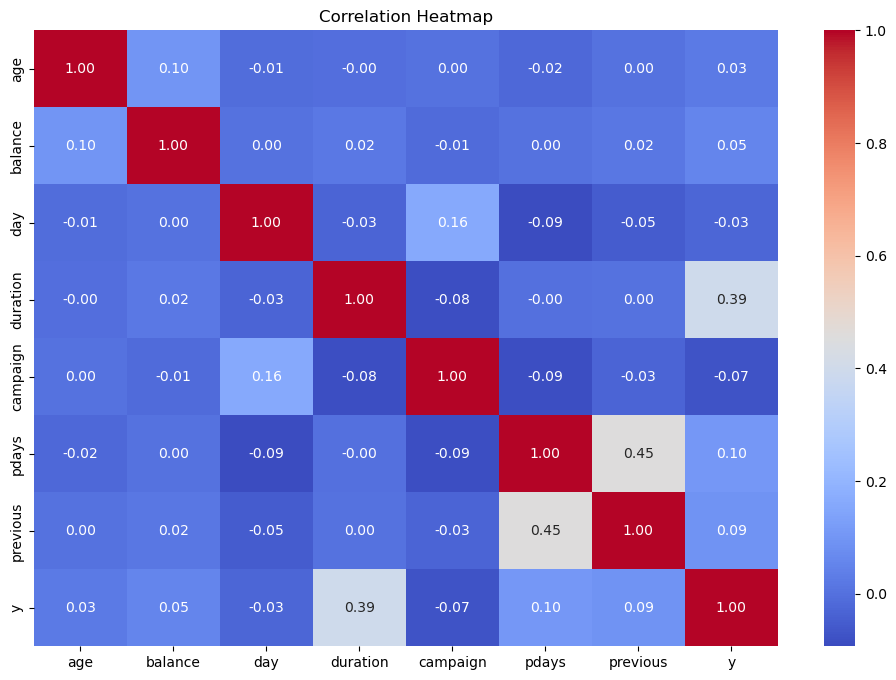

In [8]:
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(include=['int64', 'float64']).corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Correlation Heatmap")
plt.show()

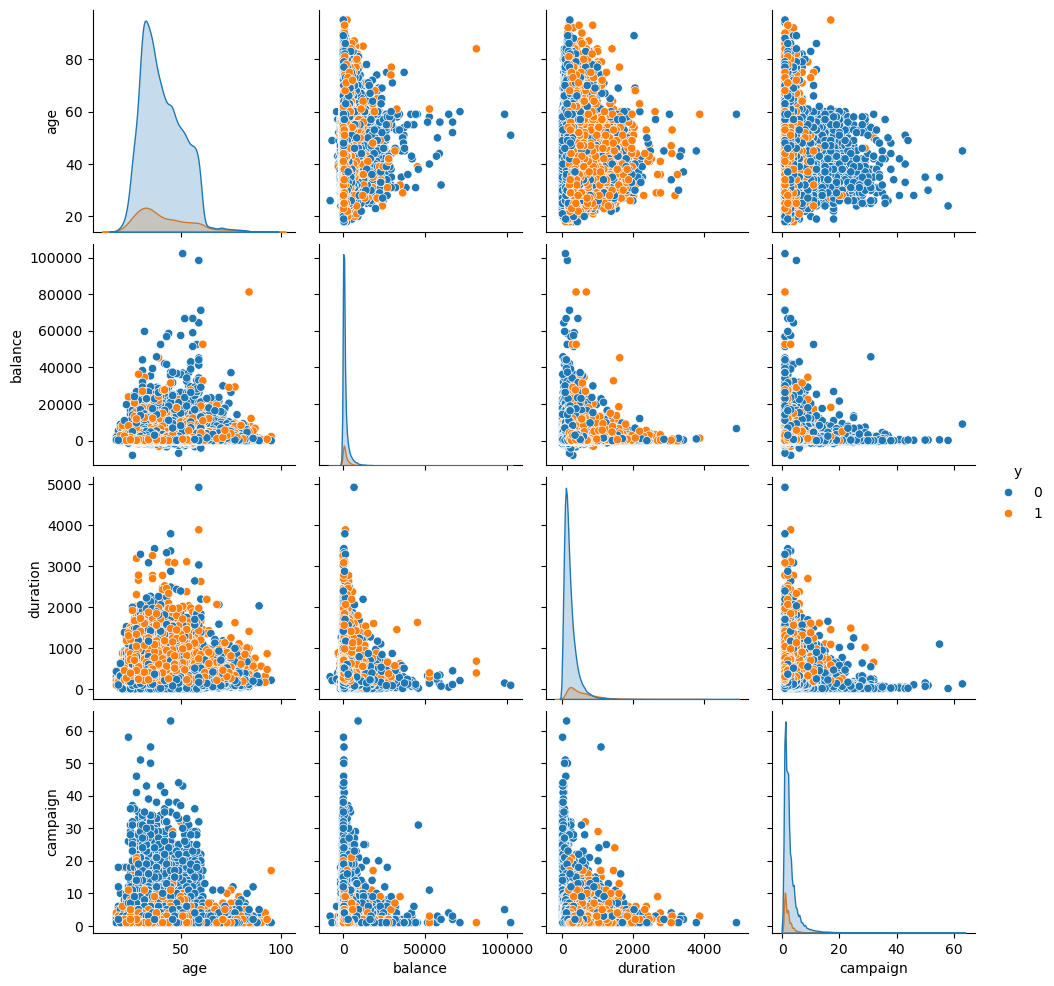

In [9]:
sns.pairplot(
    df[['age', 'balance', 'duration', 'campaign', 'y']],
    hue='y'
)

plt.show()

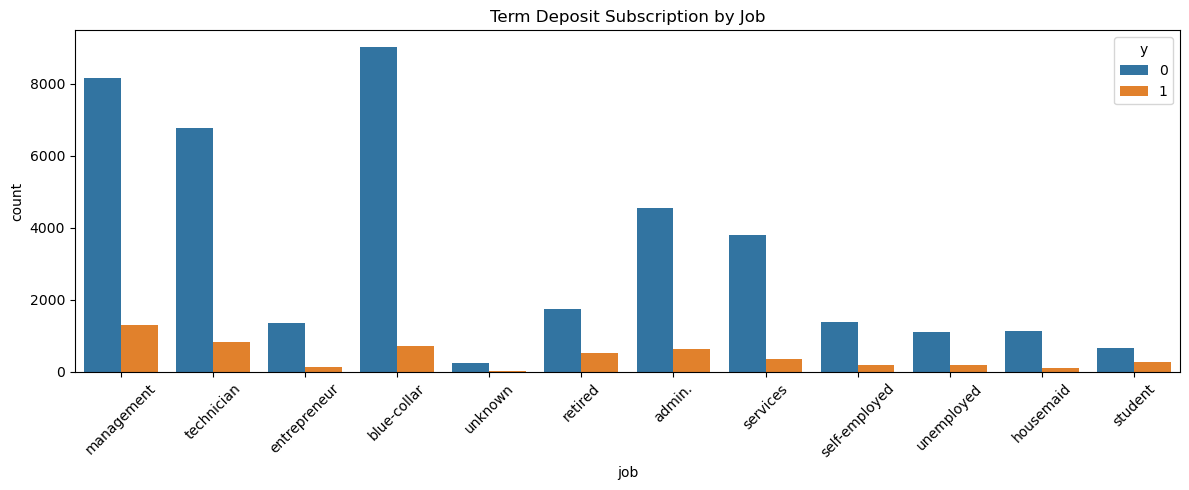

In [10]:
plt.figure(figsize=(12, 5))

sns.countplot(data=df, x='job', hue='y')

plt.title("Term Deposit Subscription by Job")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
# Remove duration to avoid data leakage
df_model = df.drop('duration', axis=1)

# Separate input features and target
X = df_model.drop('y', axis=1)
y = df_model['y']

# Convert categorical features into numerical values
X = pd.get_dummies(X, drop_first=True)

print("Features Shape:", X.shape)

Features Shape: (45211, 41)


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (36168, 41)
Testing Data: (9043, 41)


In [13]:
# Train model
model_all = RandomForestClassifier(random_state=42)

model_all.fit(X_train, y_train)

# Predict
y_pred_all = model_all.predict(X_test)

# Calculate accuracy
accuracy_all = accuracy_score(y_test, y_pred_all)

print("Accuracy using all features:", accuracy_all)

Accuracy using all features: 0.8943934534999447


In [14]:
# Select top 10 features
selector = SelectKBest(score_func=f_classif, k=10)

X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

# Display selected features
selected_features = X_train.columns[selector.get_support()]

print("Selected Features:")
print(selected_features.tolist())

Selected Features:
['pdays', 'previous', 'housing_yes', 'contact_unknown', 'month_mar', 'month_may', 'month_oct', 'month_sep', 'poutcome_success', 'poutcome_unknown']


In [15]:
# Train Random Forest using selected features
model_selected = RandomForestClassifier(random_state=42)

model_selected.fit(X_train_selected, y_train)

# Predict
y_pred_selected = model_selected.predict(X_test_selected)

# Calculate accuracy
accuracy_selected = accuracy_score(y_test, y_pred_selected)

print("Accuracy using selected features:", accuracy_selected)

Accuracy using selected features: 0.8872055733716687


In [16]:
# Compare accuracies
results = pd.DataFrame({
    'Model': ['All Features', 'Selected Features'],
    'Accuracy': [accuracy_all, accuracy_selected]
})

print(results)

               Model  Accuracy
0       All Features  0.894393
1  Selected Features  0.887206


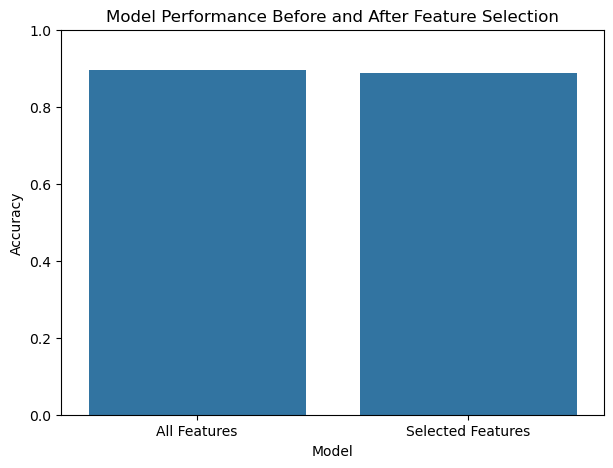

In [17]:
plt.figure(figsize=(7, 5))

sns.barplot(data=results, x='Model', y='Accuracy')

plt.title("Model Performance Before and After Feature Selection")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.show()

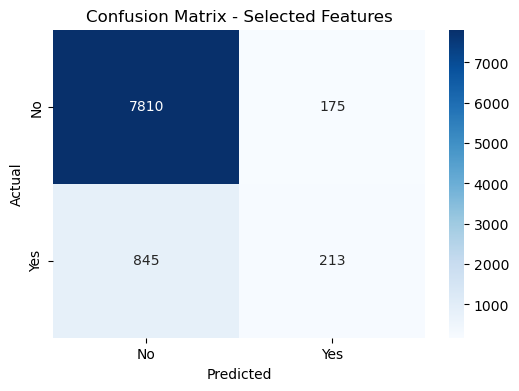

In [18]:
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test, y_pred_selected)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Selected Features")
plt.show()

In [19]:
print("Classification Report:")
print(classification_report(y_test, y_pred_selected))

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.98      0.94      7985
           1       0.55      0.20      0.29      1058

    accuracy                           0.89      9043
   macro avg       0.73      0.59      0.62      9043
weighted avg       0.86      0.89      0.86      9043



   Features  Accuracy
0         5  0.892956
1        10  0.887206
2        15  0.887316
3        20  0.862103
4        25  0.872830
5        30  0.893288


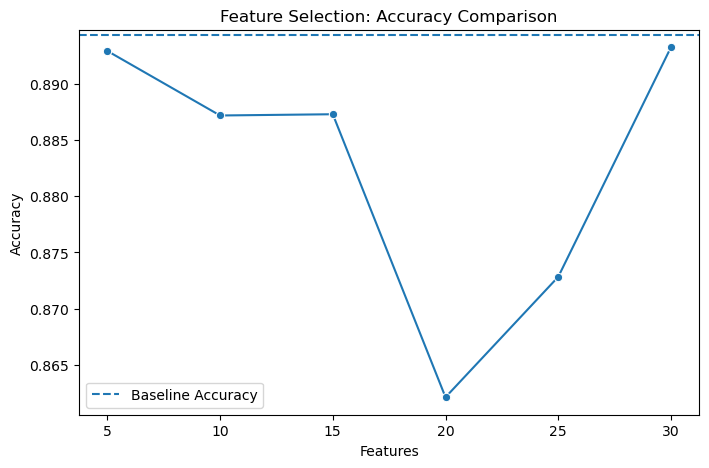

Best Number of Features: 30
Best Accuracy: 89.33 %
Baseline Accuracy: 89.44 %


In [20]:
# Find the best number of selected features

k_values = [5, 10, 15, 20, 25, 30]
accuracies = []

for k in k_values:

    selector = SelectKBest(score_func=f_classif, k=k)

    X_train_k = selector.fit_transform(X_train, y_train)
    X_test_k = selector.transform(X_test)

    model = RandomForestClassifier(random_state=42)
    model.fit(X_train_k, y_train)

    predictions = model.predict(X_test_k)

    accuracies.append(accuracy_score(y_test, predictions))

# Display results
tuning_results = pd.DataFrame({
    'Features': k_values,
    'Accuracy': accuracies
})

print(tuning_results)

# Plot comparison
plt.figure(figsize=(8, 5))
sns.lineplot(data=tuning_results, x='Features', y='Accuracy', marker='o')

plt.axhline(y=accuracy_all, linestyle='--', label='Baseline Accuracy')
plt.title("Feature Selection: Accuracy Comparison")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Best result
best_index = accuracies.index(max(accuracies))

print("Best Number of Features:", k_values[best_index])
print("Best Accuracy:", round(accuracies[best_index] * 100, 2), "%")
print("Baseline Accuracy:", round(accuracy_all * 100, 2), "%")